In [ ]:
!pip install torch torchvision numpy matplotlib scikit-learn tqdm elpv-dataset


In [ ]:
!pip install thop

In [ ]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torch.utils.data.dataloader import default_collate
from torchvision import transforms
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
from torchvision.transforms import AutoAugment, AutoAugmentPolicy
from PIL import Image
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from elpv_dataset.utils import load_dataset


In [ ]:
class ELPVDataset(Dataset):
    """
    Custom PyTorch Dataset for the ELPV solar cell dataset.
    Converts continuous probability labels to binary or multi-class labels.
    """
    def __init__(self, images, labels, cell_types, transform=None, label_type='binary'):
        self.images = images
        self.labels = labels
        self.cell_types = cell_types
        self.transform = transform
        self.label_type = label_type

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx]).convert("RGB")
        prob = self.labels[idx]

        # Binary or multi-class conversion
        if self.label_type == 'binary':
            label = 0 if prob == 0 else 1
        elif self.label_type == 'multi':
            if prob == 0: label = 0
            elif prob <= 0.4: label = 1
            elif prob <= 0.8: label = 2
            else: label = 3
        else:
            raise ValueError("Invalid label_type: choose 'binary' or 'multi'")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


In [ ]:
def get_data_loaders(batch_size=32, num_workers=2, validation_split=0.2, test_split=0.1):
    print("Loading ELPV dataset...")
    images, proba, types = load_dataset()
    print(f"Dataset loaded. Total samples: {len(images)}")

    # Transforms
    val_test_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])

    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        AutoAugment(policy=AutoAugmentPolicy.IMAGENET),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])

    # Full dataset
    num_classes = 2
    full_dataset = ELPVDataset(images, proba, types, transform=None, label_type='binary')

    # Splits
    dataset_size = len(full_dataset)
    test_size = int(test_split * dataset_size)
    val_size = int(validation_split * (dataset_size - test_size))
    train_size = dataset_size - val_size - test_size

    train_dataset, val_dataset, test_dataset = random_split(
        full_dataset, [train_size, val_size, test_size],
        generator=torch.Generator().manual_seed(42)
    )

    # Assign transforms
    train_dataset.dataset.transform = train_transform
    val_dataset.dataset.transform = val_test_transform
    test_dataset.dataset.transform = val_test_transform

    # CutMix setup
    try:
        cutmix = transforms.v2.CutMix(num_classes=num_classes, alpha=1.0)
        def collate_fn(batch): return cutmix(*default_collate(batch))
    except AttributeError:
        def collate_fn(batch): return default_collate(batch)

    # DataLoaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                             num_workers=num_workers, pin_memory=True)

    print(f"Dataset split: Train={len(train_dataset)}, Validation={len(val_dataset)}, Test={len(test_dataset)}")
    return train_loader, val_loader, test_loader, num_classes


In [ ]:
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = 3 if kernel_size == 7 else 1
        self.conv1 = nn.Conv2d(2, 1, kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv1(torch.cat([avg_out, max_out], dim=1)))

class CBAM(nn.Module):
    def __init__(self, in_planes, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, ratio)
        self.sa = SpatialAttention(kernel_size)
    def forward(self, x):
        return self.sa(self.ca(x) * x) * (self.ca(x) * x)

class EfficientNetCBAM(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        weights = EfficientNet_B3_Weights.IMAGENET1K_V1 if pretrained else None
        base_model = efficientnet_b3(weights=weights)
        self.features = nn.Sequential()
        for name, module in base_model.features.named_children():
            self.features.add_module(name, module)
            if isinstance(module, nn.Sequential):
                out_channels = None
                for sub_module in reversed(list(module.modules())):
                    if isinstance(sub_module, nn.Conv2d):
                        out_channels = sub_module.out_channels
                        break
                if out_channels: self.features.add_module(f"cbam_{name}", CBAM(out_channels))
        self.avgpool = base_model.avgpool
        in_features = [m.in_features for m in base_model.classifier if isinstance(m, nn.Linear)][0]
        self.classifier = nn.Sequential(nn.Dropout(0.3, inplace=True),
                                        nn.Linear(in_features, num_classes))
    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

def get_model2(num_classes=2):
    return EfficientNetCBAM(num_classes=num_classes, pretrained=True)



In [ ]:
# import torch
# import torch.nn as nn
# from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# class EfficientNetB0FullCBAM(nn.Module):
#     def __init__(self, num_classes=2, pretrained=True):
#         super().__init__()
#         weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
#         base_model = efficientnet_b0(weights=weights)

#         self.features = nn.Sequential()
#         for name, module in base_model.features.named_children():
#             self.features.add_module(name, module)
#             # Inject CBAM for every sequential block
#             if isinstance(module, nn.Sequential):
#                 out_ch = None
#                 for sub in reversed(list(module.modules())):
#                     if isinstance(sub, nn.Conv2d):
#                         out_ch = sub.out_channels
#                         break
#                 if out_ch:
#                     self.features.add_module(f"cbam_{name}", CBAM(out_ch, kernel_size=7))

#         self.avgpool = base_model.avgpool
#         in_features = [m.in_features for m in base_model.classifier if isinstance(m, nn.Linear)][0]
#         self.classifier = nn.Sequential(
#             nn.Dropout(0.3, inplace=True),
#             nn.Linear(in_features, num_classes)
#         )

#     def forward(self, x):
#         x = self.features(x)
#         x = self.avgpool(x)
#         x = torch.flatten(x, 1)
#         return self.classifier(x)


# def get_model2(num_classes=2):
#     return EfficientNetB0FullCBAM(num_classes=num_classes, pretrained=True)


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Reuse your existing CBAM classes
# class ChannelAttention, SpatialAttention, CBAM (only change kernel_size in SpatialAttention when instantiating CBAM)

class EfficientNetB0LightCBAM(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        base_model = efficientnet_b0(weights=weights)

        self.features = nn.Sequential()
        # Only keep last block for CBAM injection
        last_block_name, last_block_module = list(base_model.features.named_children())[-1]

        # Add all blocks normally
        for name, module in base_model.features.named_children():
            self.features.add_module(name, module)
            # Inject CBAM only in the last block
            if name == last_block_name:
                out_ch = None
                for sub in reversed(list(module.modules())):
                    if isinstance(sub, nn.Conv2d):
                        out_ch = sub.out_channels
                        break
                if out_ch:
                    # Use smaller spatial attention kernel
                    self.features.add_module(f"cbam_{name}", CBAM(out_ch, kernel_size=3))

        self.avgpool = base_model.avgpool
        in_features = [m.in_features for m in base_model.classifier if isinstance(m, nn.Linear)][0]
        self.classifier = nn.Sequential(
            nn.Dropout(0.3, inplace=True),
            nn.Linear(in_features, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

def get_model3(num_classes=2):
    return EfficientNetB0LightCBAM(num_classes=num_classes, pretrained=True)


In [ ]:
import torch
import torch.nn as nn
import timm

class XceptionModel(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        # Load Xception backbone from timm
        base_model = timm.create_model("legacy_xception", pretrained=pretrained, num_classes=0, global_pool="avg")

        # Stem
        self.stem = nn.Sequential(
            base_model.conv1,
            base_model.bn1,
            base_model.act1,
            base_model.conv2,
            base_model.bn2,
            base_model.act2,
        )

        # Main blocks
        self.blocks = nn.Sequential(
            base_model.block1,
            base_model.block2,
            base_model.block3,
            base_model.block4,
            base_model.block5,
            base_model.block6,
            base_model.block7,
            base_model.block8,
            base_model.block9,
            base_model.block10,
            base_model.block11,
        )

        # Final convolution, batch norm, activation
        self.conv4 = base_model.conv4
        self.bn4 = base_model.bn4
        self.act4 = base_model.act4

        # Pooling and classifier
        self.pool = base_model.global_pool
        in_features = base_model.num_features
        self.classifier = nn.Linear(in_features, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        x = self.conv4(x)
        x = self.bn4(x)
        x = self.act4(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

def get_model(num_classes=2):
    model = timm.create_model(
        "legacy_xception",
        pretrained=True,
        num_classes=num_classes,  # directly set classifier output
        global_pool="avg"
    )
    return model


In [ ]:
import torch
import torch.nn as nn
import timm

class Xception71Model(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()
        # Load Xception-71 backbone
        self.base_model = timm.create_model(
            "xception71",
            pretrained=pretrained,
            num_classes=num_classes,  # direct classifier output
            global_pool="avg"
        )

    def forward(self, x):
        return self.base_model(x)

def get_model4(num_classes=2):
    return Xception71Model(num_classes=num_classes, pretrained=True)


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32
NUM_EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5
NUM_WORKERS = 2
SAVE_DIR = "checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

def train_one_epoch(model, loader, loss_fn, optimizer, device, scaler):
    model.train()
    total_loss, all_preds, all_labels = 0, [], []
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        with torch.cuda.amp.autocast():
            outputs = model(images)
            loss = loss_fn(outputs, labels)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return total_loss / len(loader), accuracy_score(all_labels, all_preds)

def validate_one_epoch(model, loader, loss_fn, device):
    model.eval()
    total_loss, all_preds, all_labels = 0, [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validating", leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            total_loss += loss.item()
            all_preds.extend(outputs.argmax(1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    avg_loss = total_loss / len(loader)
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='binary')
    return avg_loss, acc, precision, recall, f1


In [ ]:
# import torch
# import torch.nn as nn
# from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

# class MobileNetCBAM(nn.Module):
#     def __init__(self, num_classes=2, pretrained=True):
#         super().__init__()
#         weights = MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
#         base_model = mobilenet_v2(weights=weights)

#         self.features = nn.Sequential()
#         for name, module in base_model.features.named_children():
#             self.features.add_module(name, module)

#             # Inject CBAM after each top-level module (like EfficientNetCBAM)
#             out_ch = None
#             for sub in reversed(list(module.modules())):
#                 if isinstance(sub, nn.Conv2d):
#                     out_ch = sub.out_channels
#                     break
#             if out_ch:
#                 self.features.add_module(f"cbam_{name}", CBAM(out_ch))

#         self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
#         in_features = base_model.classifier[1].in_features
#         self.classifier = nn.Sequential(
#             nn.Dropout(0.2, inplace=True),
#             nn.Linear(in_features, num_classes)
#         )

#     def forward(self, x):
#         x = self.features(x)
#         x = self.avgpool(x)
#         x = torch.flatten(x, 1)
#         return self.classifier(x)

# # Example usage
# def get_model(num_classes=2):
#     return MobileNetCBAM(num_classes=num_classes, pretrained=True)


In [ ]:
train_loader, val_loader, _, num_classes = get_data_loaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
model = get_model(num_classes=num_classes).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

# ✅ New history lists with _1 suffix
train_loss_1, val_loss_1 = [], []
train_acc_1, val_acc_1 = [], []
val_f1_1 = []

best_val_f1 = 0
for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer, DEVICE, scaler)
    val_loss, val_acc, val_precision, val_recall, val_f1 = validate_one_epoch(model, val_loader, loss_fn, DEVICE)
    scheduler.step()

    # Store in _1 lists
    train_loss_1.append(train_loss)
    val_loss_1.append(val_loss)
    train_acc_1.append(train_acc)
    val_acc_1.append(val_acc)
    val_f1_1.append(val_f1)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
          f"Val Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f} | Time={time.time()-start:.2f}s")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        save_path = os.path.join(SAVE_DIR, "best_model.pth")
        torch.save(model.state_dict(), save_path)
        print(f"New best model saved at {save_path} (F1={best_val_f1:.4f})")


Loading ELPV dataset...
Dataset loaded. Total samples: 2624
Dataset split: Train=1890, Validation=472, Test=262


/tmp/ipython-input-1134276808.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/50 | Train Loss=0.5722, Acc=0.7275 | Val Loss=0.5242, Acc=0.7585, F1=0.7121 | Time=18.06s
New best model saved at checkpoints/best_model.pth (F1=0.7121)


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 2/50 | Train Loss=0.4095, Acc=0.8714 | Val Loss=0.4826, Acc=0.8008, F1=0.7707 | Time=15.40s
New best model saved at checkpoints/best_model.pth (F1=0.7707)


...

Epoch 48/50 | Train Loss=0.2024, Acc=1.0000 | Val Loss=0.4979, Acc=0.8369, F1=0.7936 | Time=14.58s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 49/50 | Train Loss=0.2115, Acc=0.9995 | Val Loss=0.4926, Acc=0.8305, F1=0.7861 | Time=14.63s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
                                                           

Epoch 50/50 | Train Loss=0.2048, Acc=0.9989 | Val Loss=0.4925, Acc=0.8390, F1=0.7957 | Time=14.55s


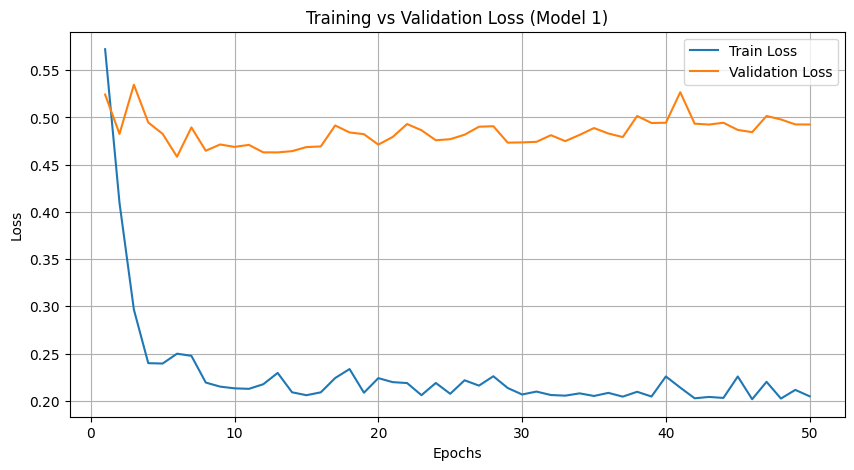

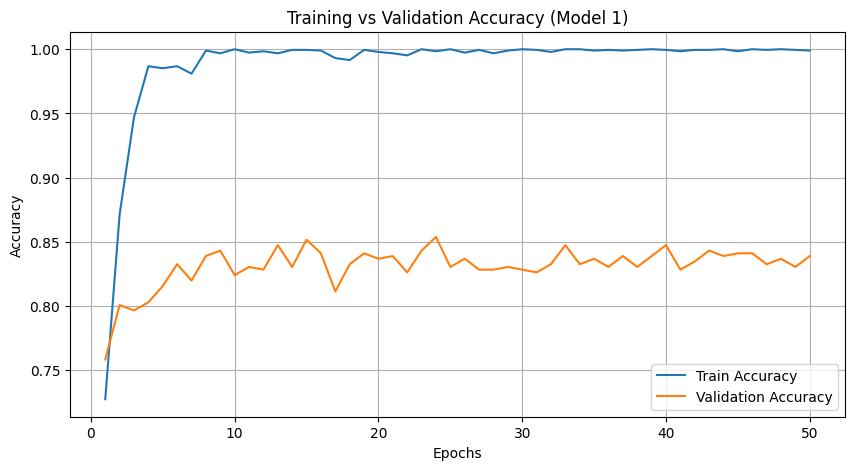

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# Plot Loss
plt.figure(figsize=(10,5))
plt.plot(epochs, train_loss_1, label="Train Loss")
plt.plot(epochs, val_loss_1, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss (Model 1)")
plt.legend()
plt.grid(True)
plt.show()

# Plot Accuracy
plt.figure(figsize=(10,5))
plt.plot(epochs, train_acc_1, label="Train Accuracy")
plt.plot(epochs, val_acc_1, label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy (Model 1)")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from thop import profile
from thop import clever_format

# Example input size (your ELPV dataset is grayscale resized to 300x300)
dummy_input = torch.randn(1, 3, 300, 300).to(DEVICE)

model_1 = get_model(num_classes=2).to(DEVICE)
flops, params = profile(model_1, inputs=(dummy_input,))
flops, params = clever_format([flops, params], "%.3f")

print(f"Model FLOPs: {flops}, Parameters: {params}")


[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.MaxPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
Model FLOPs: 8.440G, Parameters: 20.811M


In [ ]:
train_loader, val_loader, _, num_classes = get_data_loaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
model = get_model4(num_classes=num_classes).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

# ✅ New history lists with _1 suffix
train_loss_1, val_loss_1 = [], []
train_acc_1, val_acc_1 = [], []
val_f1_1 = []

best_val_f1 = 0
for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, loss_fn, optimizer, DEVICE, scaler)
    val_loss, val_acc, val_precision, val_recall, val_f1 = validate_one_epoch(model, val_loader, loss_fn, DEVICE)
    scheduler.step()

    # Store in _1 lists
    train_loss_1.append(train_loss)
    val_loss_1.append(val_loss)
    train_acc_1.append(train_acc)
    val_acc_1.append(val_acc)
    val_f1_1.append(val_f1)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
          f"Val Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f} | Time={time.time()-start:.2f}s")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        save_path = os.path.join(SAVE_DIR, "best_model.pth")
        torch.save(model.state_dict(), save_path)
        print(f"New best model saved at {save_path} (F1={best_val_f1:.4f})")


Loading ELPV dataset...
Dataset loaded. Total samples: 2624
Dataset split: Train=1890, Validation=472, Test=262


/tmp/ipython-input-1082311400.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/50 | Train Loss=0.5763, Acc=0.7111 | Val Loss=0.6089, Acc=0.7246, F1=0.6649 | Time=29.08s
New best model saved at checkpoints/best_model.pth (F1=0.6649)


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 2/50 | Train Loss=0.4113, Acc=0.8646 | Val Loss=0.5546, Acc=0.7712, F1=0.6983 | Time=28.55s
New best model saved at checkpoints/best_model.pth (F1=0.6983)


...

Epoch 48/50 | Train Loss=0.2024, Acc=1.0000 | Val Loss=0.6077, Acc=0.7945, F1=0.7467 | Time=27.29s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 49/50 | Train Loss=0.2207, Acc=0.9989 | Val Loss=0.6211, Acc=0.7987, F1=0.7453 | Time=27.43s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
                                                           

Epoch 50/50 | Train Loss=0.2020, Acc=1.0000 | Val Loss=0.6211, Acc=0.7924, F1=0.7380 | Time=27.48s


In [ ]:
from thop import profile
from thop import clever_format

# Example input size (your ELPV dataset is grayscale resized to 300x300)
dummy_input = torch.randn(1, 3, 300, 300).to(DEVICE)

model_4 = get_model4(num_classes=2).to(DEVICE)
flops, params = profile(model_4, inputs=(dummy_input,))
flops, params = clever_format([flops, params], "%.3f")

print(f"Model FLOPs: {flops}, Parameters: {params}")


[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
Model FLOPs: 18.200G, Parameters: 40.287M


In [ ]:
train_loader, val_loader, _, num_classes = get_data_loaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
model2 = get_model2(num_classes=num_classes).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model2.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

best_val_f1 = 0
for epoch in range(NUM_EPOCHS):
  start = time.time()
  train_loss, train_acc = train_one_epoch(model2, train_loader, loss_fn, optimizer, DEVICE, scaler)
  val_loss, val_acc, val_precision, val_recall, val_f1 = validate_one_epoch(model2, val_loader, loss_fn, DEVICE)
  scheduler.step()
  print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
  f"Val Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f} | Time={time.time()-start:.2f}s")
  if val_f1 > best_val_f1:
     best_val_f1 = val_f1
     save_path = os.path.join(SAVE_DIR, "best_model2.pth")
     torch.save(model2.state_dict(), save_path)
     print(f"New best model saved at {save_path} (F1={best_val_f1:.4f})")



Loading ELPV dataset...
Dataset loaded. Total samples: 2624
Dataset split: Train=1890, Validation=472, Test=262


/tmp/ipython-input-1463469729.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/50 | Train Loss=0.6818, Acc=0.5651 | Val Loss=0.6877, Acc=0.5890, F1=0.0202 | Time=14.68s
New best model saved at checkpoints/best_model2.pth (F1=0.0202)


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 2/50 | Train Loss=0.6811, Acc=0.5841 | Val Loss=0.6735, Acc=0.5805, F1=0.2556 | Time=15.00s
New best model saved at checkpoints/best_model2.pth (F1=0.2556)


...

Epoch 48/50 | Train Loss=0.4285, Acc=0.8481 | Val Loss=0.6504, Acc=0.7076, F1=0.6368 | Time=15.65s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 49/50 | Train Loss=0.4485, Acc=0.8392 | Val Loss=0.6431, Acc=0.7034, F1=0.6552 | Time=14.69s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
                                                           

Epoch 50/50 | Train Loss=0.4285, Acc=0.8460 | Val Loss=0.6626, Acc=0.6822, F1=0.6231 | Time=14.86s


In [ ]:
from thop import profile
from thop import clever_format

# Example input size (your ELPV dataset is grayscale resized to 300x300)
dummy_input = torch.randn(1, 3, 300, 300).to(DEVICE)

model_2 = get_model2(num_classes=2).to(DEVICE)
flops, params = profile(model_2, inputs=(dummy_input,))
flops, params = clever_format([flops, params], "%.3f")

print(f"Model FLOPs: {flops}, Parameters: {params}")


[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.AdaptiveMaxPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
Model FLOPs: 1.940G, Parameters: 11.024M


In [ ]:
train_loader, val_loader, _, num_classes = get_data_loaders(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
model3 = get_model3(num_classes=num_classes).to(DEVICE)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model3.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler = torch.cuda.amp.GradScaler()

# ✅ History dictionary
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_f1": []
}

best_val_f1 = 0
for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_loss, train_acc = train_one_epoch(model3, train_loader, loss_fn, optimizer, DEVICE, scaler)
    val_loss, val_acc, val_precision, val_recall, val_f1 = validate_one_epoch(model3, val_loader, loss_fn, DEVICE)
    scheduler.step()

    # Save history
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss={train_loss:.4f}, Acc={train_acc:.4f} | "
          f"Val Loss={val_loss:.4f}, Acc={val_acc:.4f}, F1={val_f1:.4f} | Time={time.time()-start:.2f}s")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        save_path = os.path.join(SAVE_DIR, "best_model3.pth")
        torch.save(model3.state_dict(), save_path)
        print(f"New best model saved at {save_path} (F1={best_val_f1:.4f})")

Loading ELPV dataset...
Dataset loaded. Total samples: 2624
Dataset split: Train=1890, Validation=472, Test=262


/tmp/ipython-input-2395530002.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/50 | Train Loss=0.6295, Acc=0.6989 | Val Loss=0.5733, Acc=0.7309, F1=0.6443 | Time=16.03s
New best model saved at checkpoints/best_model3.pth (F1=0.6443)


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 2/50 | Train Loss=0.5251, Acc=0.7683 | Val Loss=0.5309, Acc=0.7352, F1=0.6719 | Time=10.64s
New best model saved at checkpoints/best_model3.pth (F1=0.6719)


...

Epoch 48/50 | Train Loss=0.2039, Acc=0.9995 | Val Loss=0.5418, Acc=0.8263, F1=0.7887 | Time=9.64s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 49/50 | Train Loss=0.2115, Acc=0.9968 | Val Loss=0.5360, Acc=0.8347, F1=0.7947 | Time=9.08s


Training:   0%|          | 0/60 [00:00<?, ?it/s]/tmp/ipython-input-1845615484.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
                                                           

Epoch 50/50 | Train Loss=0.2230, Acc=0.9958 | Val Loss=0.5395, Acc=0.8347, F1=0.7979 | Time=9.11s


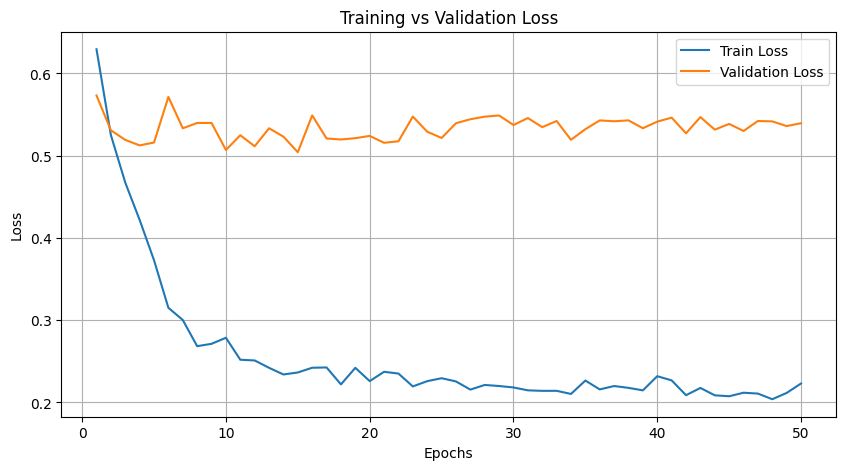

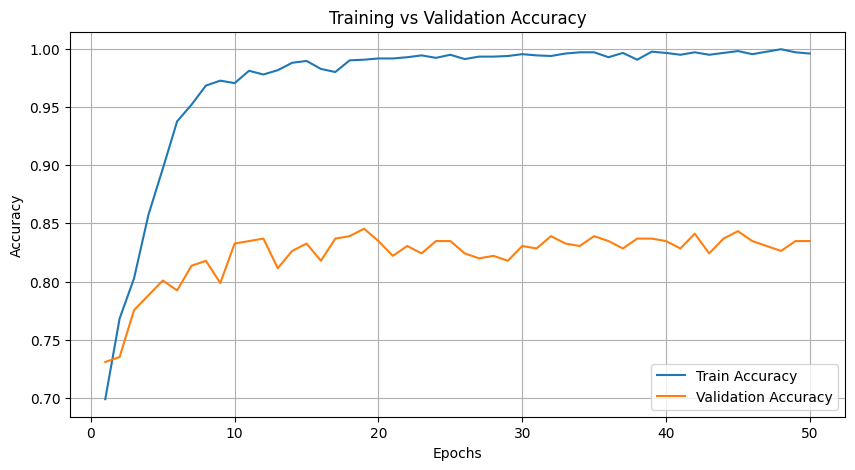

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# Plot Loss
plt.figure(figsize=(10,5))
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot Accuracy
plt.figure(figsize=(10,5))
plt.plot(epochs, history["train_acc"], label="Train Accuracy")
plt.plot(epochs, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from thop import profile
from thop import clever_format

# Example input size (your ELPV dataset is grayscale resized to 300x300)
dummy_input = torch.randn(1, 3, 300, 300).to(DEVICE)

model_3 = get_model3(num_classes=2).to(DEVICE)
flops, params = profile(model_3, inputs=(dummy_input,))
flops, params = clever_format([flops, params], "%.3f")

print(f"Model FLOPs: {flops}, Parameters: {params}")


[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.AdaptiveMaxPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.dropout.Dropout'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
Model FLOPs: 783.407M, Parameters: 4.215M


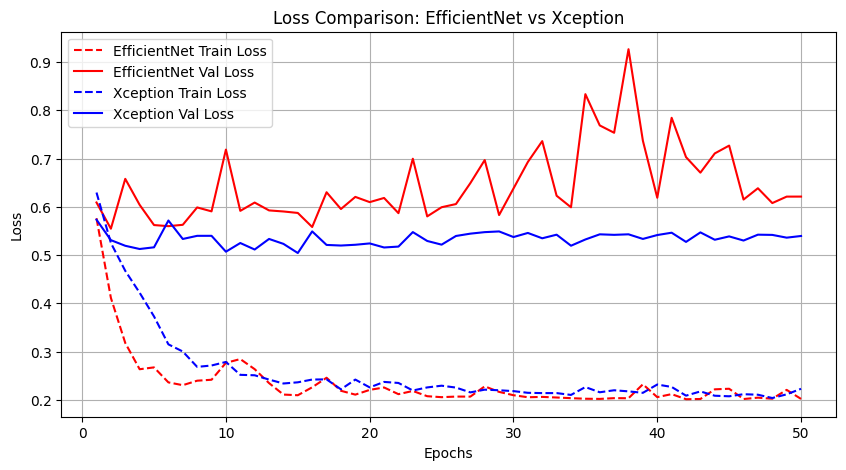

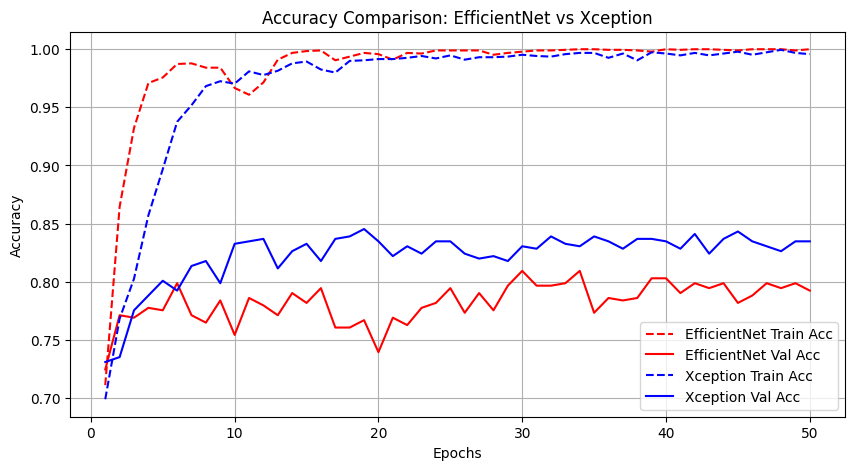

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, NUM_EPOCHS + 1)

# =========================
# 📊 Comparison of Loss
# =========================
plt.figure(figsize=(10,5))
plt.plot(epochs, train_loss_1, label="EfficientNet Train Loss", linestyle="--", color="red")
plt.plot(epochs, val_loss_1, label="EfficientNet Val Loss", linestyle="-", color="red")
plt.plot(epochs, history["train_loss"], label="Xception Train Loss", linestyle="--", color="blue")
plt.plot(epochs, history["val_loss"], label="Xception Val Loss", linestyle="-", color="blue")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Comparison: EfficientNet vs Xception")
plt.legend()
plt.grid(True)
plt.show()

# =========================
# 📊 Comparison of Accuracy
# =========================
plt.figure(figsize=(10,5))
plt.plot(epochs, train_acc_1, label="EfficientNet Train Acc", linestyle="--", color="red")
plt.plot(epochs, val_acc_1, label="EfficientNet Val Acc", linestyle="-", color="red")
plt.plot(epochs, history["train_acc"], label="Xception Train Acc", linestyle="--", color="blue")
plt.plot(epochs, history["val_acc"], label="Xception Val Acc", linestyle="-", color="blue")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison: EfficientNet vs Xception")
plt.legend()
plt.grid(True)
plt.show()


# 🔍 Explainable AI (XAI) with Grad-CAM for Automated PV Cell Inspection

### Why Grad-CAM?
In automated photovoltaic (PV) solar cell inspection, black-box predictions are insufficient for manufacturing and QA pipelines. Inspection engineers need to know **where** and **why** the deep learning model flags a solar cell as defective (e.g. micro-cracks, finger interruptions, cell fractures, or degradation zones).

**Grad-CAM (Gradient-weighted Class Activation Mapping)** calculates gradients of the target class score with respect to the feature activation maps of the final convolutional layer. This produces a coarse localization heatmap highlighting the exact discriminative regions of the PV cell:
- 🟢 **Functional Cells:** Diffuse or low-magnitude activations across regular grid patterns.
- 🔴 **Defective Cells:** High-intensity activation hotspots localized directly over cracks, inactive fingers, or localized luminescence loss.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

class GradCAM:
    """
    Grad-CAM: Gradient-weighted Class Activation Mapping for PyTorch models.
    Supports any CNN architecture (Xception, EfficientNet, CBAM, MobileNet, etc.).
    """
    def __init__(self, model, target_layer=None):
        self.model = model
        self.model.eval()
        self.gradients = None
        self.activations = None
        
        # Auto-detect the last Conv2d layer if target_layer is not explicitly given
        if target_layer is None:
            target_layer = self._find_last_conv_layer(model)
        self.target_layer = target_layer
        
        # Register forward and backward hooks
        self.forward_handle = self.target_layer.register_forward_hook(self._forward_hook)
        self.backward_handle = self.target_layer.register_full_backward_hook(self._backward_hook)
    
    def _find_last_conv_layer(self, module):
        last_conv = None
        for m in module.modules():
            if isinstance(m, nn.Conv2d):
                last_conv = m
        if last_conv is None:
            raise ValueError("No Conv2d layer found in model for Grad-CAM.")
        return last_conv
    
    def _forward_hook(self, module, input, output):
        self.activations = output.detach()
        
    def _backward_hook(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()
        
    def generate_cam(self, input_tensor, target_class=None):
        """
        Generate Grad-CAM activation heatmap for a single input image tensor.
        Args:
            input_tensor: (1, C, H, W) normalized tensor
            target_class: int class index or None (uses argmax predicted class)
        Returns:
            cam: (H, W) normalized float heatmap in range [0, 1]
            target_class: class used for backpropagation
            probabilities: softmax class probabilities
        """
        self.model.zero_grad()
        output = self.model(input_tensor)
        probs = torch.softmax(output, dim=1)[0].detach().cpu().numpy()
        
        if target_class is None:
            target_class = output.argmax(dim=1).item()
            
        # Backward pass with respect to the target class logit
        score = output[0, target_class]
        score.backward(retain_graph=True)
        
        # Global Average Pooling of gradients across spatial dimensions (H, W)
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)  # (1, C, 1, 1)
        
        # Linear combination of feature map activations weighted by importance
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)  # (1, 1, H', W')
        
        # ReLU: retain only features that positively correlate with the target class
        cam = F.relu(cam)
        
        # Upsample to match original input image resolution
        cam = F.interpolate(cam, size=input_tensor.shape[2:], mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        
        # Min-Max Normalization to [0, 1]
        cam_min, cam_max = cam.min(), cam.max()
        if cam_max - cam_min > 1e-8:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)
            
        return cam, target_class, probs
    
    def remove_hooks(self):
        """Clean up hooks when done."""
        self.forward_handle.remove()
        self.backward_handle.remove()

def unnormalize_image(tensor):
    """
    Converts ImageNet-normalized tensor (C, H, W) back to [0, 1] RGB image array (H, W, C).
    """
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().permute(1, 2, 0).numpy()
    img = img * std + mean
    return np.clip(img, 0, 1)

def overlay_cam_on_image(img, cam, alpha=0.45, colormap='jet'):
    """
    Blends the normalized Grad-CAM heatmap with the input solar cell image.
    """
    cmap = plt.get_cmap(colormap)
    heatmap = cmap(cam)[:, :, :3]  # (H, W, 3)
    overlay = alpha * heatmap + (1.0 - alpha) * img
    overlay = np.clip(overlay, 0, 1)
    return heatmap, overlay


In [ ]:
def visualize_pv_gradcam(model, data_loader, num_samples=6, device='cuda', target_layer=None):
    """
    Visualizes side-by-side Grad-CAM explanations for PV cell samples.
    Columns:
      1. Original PV Cell Image (EL) with Ground Truth
      2. Grad-CAM Activation Heatmap
      3. Heatmap Overlaid on PV Cell with Predicted Class & Confidence
    """
    grad_cam = GradCAM(model, target_layer=target_layer)
    class_names = ["Functional (No Defect)", "Defective (Fault/Crack)"]
    
    samples_found = 0
    fig, axes = plt.subplots(num_samples, 3, figsize=(13, 3.8 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)
        
    for images, labels in data_loader:
        for i in range(images.size(0)):
            if samples_found >= num_samples:
                break
                
            img_tensor = images[i:i+1].to(device)
            true_label = labels[i].item()
            
            cam, pred_class, probs = grad_cam.generate_cam(img_tensor)
            orig_img = unnormalize_image(images[i])
            heatmap, overlay = overlay_cam_on_image(orig_img, cam, alpha=0.45)
            
            is_correct = (pred_class == true_label)
            status = "✅ CORRECT" if is_correct else "❌ INCORRECT"
            
            # Column 1: Original Cell Image
            axes[samples_found, 0].imshow(orig_img)
            axes[samples_found, 0].set_title(f"Cell #{samples_found+1}\nGround Truth: {class_names[true_label]}", fontsize=11, fontweight='bold')
            axes[samples_found, 0].axis('off')
            
            # Column 2: Pure Grad-CAM Heatmap
            axes[samples_found, 1].imshow(cam, cmap='jet')
            axes[samples_found, 1].set_title("Grad-CAM Heatmap\n(Defect Localization)", fontsize=11)
            axes[samples_found, 1].axis('off')
            
            # Column 3: Blended Overlay with Model Prediction
            axes[samples_found, 2].imshow(overlay)
            status_color = "#008000" if is_correct else "#cc0000"
            axes[samples_found, 2].set_title(
                f"Overlay [{status}]\nPred: {class_names[pred_class]} ({probs[pred_class]:.1%})",
                fontsize=11,
                fontweight='bold',
                color=status_color
            )
            axes[samples_found, 2].axis('off')
            
            samples_found += 1
            
        if samples_found >= num_samples:
            break
            
    plt.tight_layout()
    plt.suptitle("🔍 Automated PV Cell Inspection - Grad-CAM Explainability Heatmaps", fontsize=15, fontweight='bold', y=1.01)
    plt.show()
    grad_cam.remove_hooks()


In [ ]:
# 🚀 Run Grad-CAM Explainability on the Trained Model
# Automatically selects the active trained model (model3, model2, or model)
active_model = None
model_name = ""

if "model3" in locals():
    active_model = model3
    model_name = "EfficientNet-B0 + Light CBAM (model3)"
elif "model2" in locals():
    active_model = model2
    model_name = "EfficientNet-B3 + CBAM (model2)"
elif "model" in locals():
    active_model = model
    model_name = "Xception (model)"

if active_model is not None:
    print(f"Executing Grad-CAM on active model: {model_name}")
    print("Generating explainability heatmaps for validation PV cells...")
    visualize_pv_gradcam(
        model=active_model,
        data_loader=val_loader,
        num_samples=6,
        device=DEVICE
    )
else:
    print("No active model found in environment. Please train or load a model checkpoint first.")


In [ ]:
def inspect_single_cell(model, image_tensor, true_label=None, device=DEVICE):
    """
    Interactive helper to inspect any individual PV solar cell with Grad-CAM.
    """
    grad_cam = GradCAM(model)
    if image_tensor.dim() == 3:
        image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)
    
    cam, pred_class, probs = grad_cam.generate_cam(image_tensor)
    orig_img = unnormalize_image(image_tensor.squeeze(0))
    heatmap, overlay = overlay_cam_on_image(orig_img, cam, alpha=0.45)
    class_names = ["Functional (No Defect)", "Defective (Fault/Crack)"]
    
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 3, 1)
    plt.imshow(orig_img)
    title = "Original PV Cell (EL)"
    if true_label is not None:
        title += f"\nGround Truth: {class_names[true_label]}"
    plt.title(title, fontsize=11, fontweight='bold')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.imshow(cam, cmap='jet')
    plt.title("Grad-CAM Heatmap\n(Hotspots = Defect Regions)", fontsize=11)
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    is_correct = (true_label is None) or (pred_class == true_label)
    plt.title(
        f"Overlay Explanation\nPred: {class_names[pred_class]} ({probs[pred_class]:.2%})",
        fontsize=11,
        fontweight='bold',
        color="#008000" if is_correct else "#cc0000"
    )
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    grad_cam.remove_hooks()

# Demonstration on individual validation samples
if active_model is not None:
    print("🔎 Individual PV Cell Inspection Examples:")
    for images, labels in val_loader:
        for idx in range(min(3, images.size(0))):
            inspect_single_cell(active_model, images[idx], true_label=labels[idx].item())
        break
